In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import scipy.stats as stats

In [2]:
df_yearly = pd.read_csv('../Data/Hospital/annual_deaths_by_clinic.csv')
df_monthly = pd.read_csv('../Data/Hospital/monthly_deaths.csv', parse_dates=['date'])

In [ ]:
df_monthly.head(3)

In [25]:
df_yearly.head(3)

,year,births,deaths,clinic
0,1841,3036,237,clinic 1
1,1842,3287,518,clinic 1
2,1843,3060,274,clinic 1


---
**Chance of Dying in Childbirth**

In [3]:
prob = df_yearly.deaths.sum() / df_yearly.births.sum() * 100
f'{prob:.3}%'

'7.08%'

**Annual Births & Deaths of Clinics**

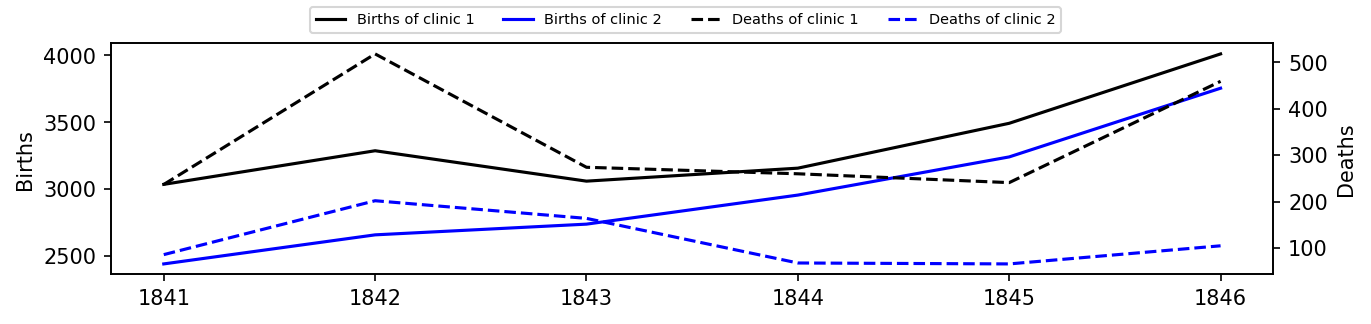

In [46]:
fig = plt.figure(figsize=(10,2), dpi=150)

ax1 = plt.gca()
ax2 = ax1.twinx()

def clinic_color(clinic):
    if clinic == 'clinic 1':
        return 'black'
    else:
        return 'blue'

for c in df_yearly.clinic.unique():
    x = df_yearly[df_yearly.clinic == c].year
    y = df_yearly[df_yearly.clinic == c].births
    y2 = df_yearly[df_yearly.clinic == c].deaths
    ax1.plot(x,y, label=f'Births of {c}', color=clinic_color(c))
    ax1.set_ylabel('Births')
    ax2.plot(x,y2, label=f'Deaths of {c}', linestyle='--', color=clinic_color(c))
    ax2.set_ylabel('Deaths')
    
fig.legend(fontsize=7,ncol=4, loc='upper center')

In [14]:
df_monthly.births.min()

190

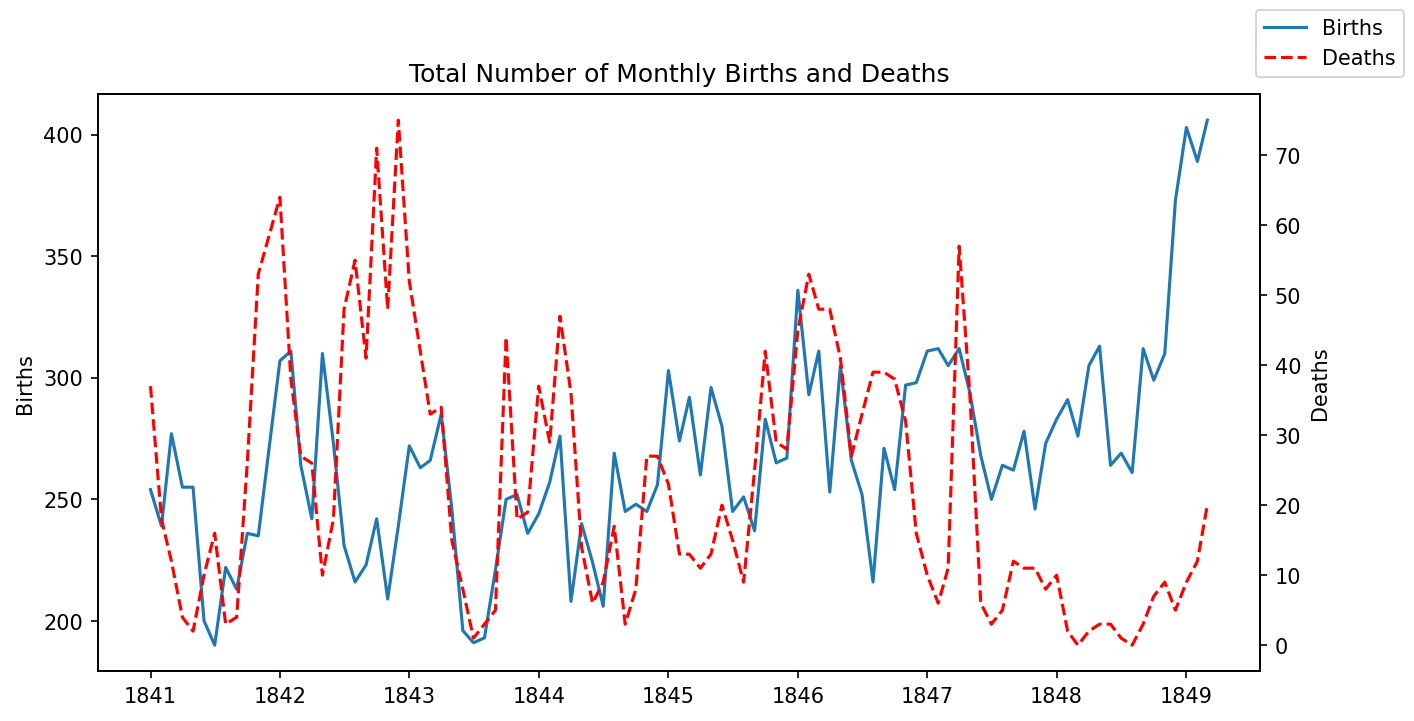

In [24]:
fig = plt.figure(figsize=(10, 5), dpi=150)

ax1 = plt.gca()
ax2 = ax1.twinx()

ax1.plot(df_monthly.date,df_monthly.births, label='Births')
ax1.set_ylabel('Births')

ax2.plot(df_monthly.date,df_monthly.deaths, label='Deaths', linestyle='--', color='red')
ax2.set_ylabel('Deaths')


plt.title('Total Number of Monthly Births and Deaths')
fig.legend()

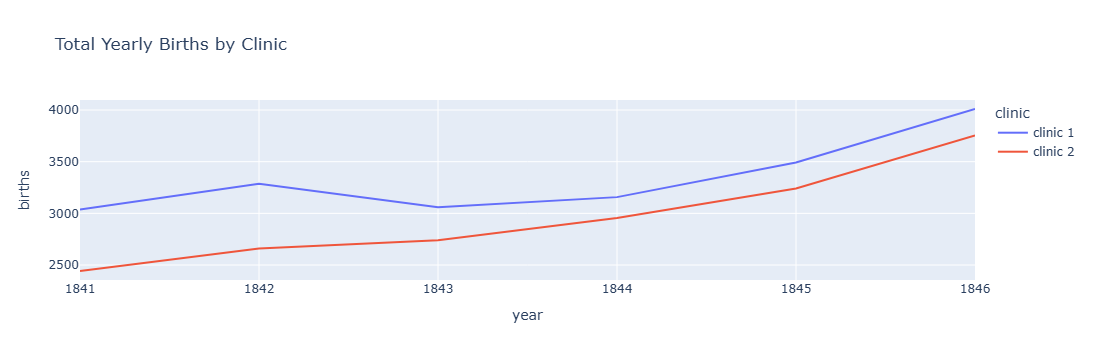

In [49]:
line = px.line(df_yearly, 
               x='year', 
               y='births',
               color='clinic',
               title='Total Yearly Births by Clinic')
line.show()